# Exploratory Data Analysis (EDA)

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 



In [3]:
df = pd.read_csv("../data/cleaned_housing_data.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(250000, 24)


## Price & Size Analysis

1. What is the distribution of property prices?

In [4]:
df["Price_in_Lakhs"].describe()

count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64

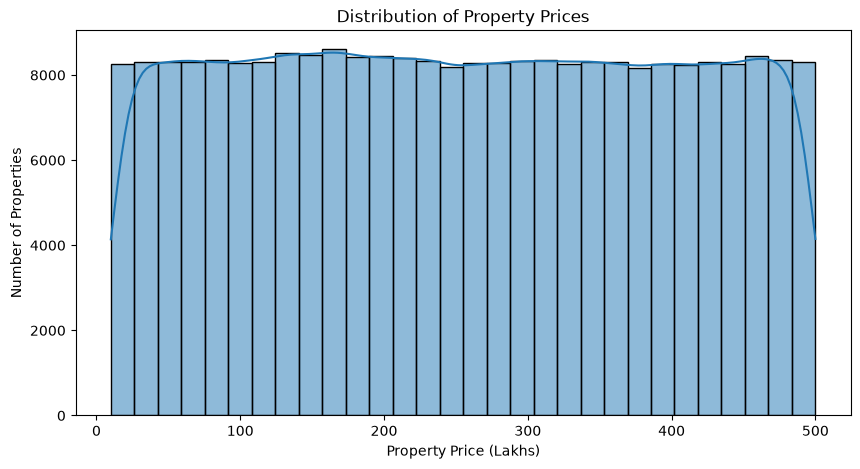

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price_in_Lakhs",
    bins=30,
    kde=True
)

plt.title("Distribution of Property Prices")
plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Number of Properties")

plt.show()

"The histogram represents the distribution of property prices in the Indian housing dataset. It helps identify the most common price ranges and understand the spread of property prices."

In [6]:
price_bins = pd.cut(
    df["Price_in_Lakhs"],
    bins=10
)

print(price_bins.value_counts().sort_index())

Price_in_Lakhs
(9.51, 59.0]      24894
(59.0, 108.0]     24952
(108.0, 157.0]    25299
(157.0, 206.0]    25465
(206.0, 255.0]    24945
(255.0, 304.0]    24900
(304.0, 353.0]    24943
(353.0, 402.0]    24725
(402.0, 451.0]    24789
(451.0, 500.0]    25088
Name: count, dtype: int64


This will tell us how many properties belong to each price range.

2. What is the distribution of property sizes?

In [7]:
df["Size_in_SqFt"].describe()

count    250000.000000
mean       2749.813216
std        1300.606954
min         500.000000
25%        1623.000000
50%        2747.000000
75%        3874.000000
max        5000.000000
Name: Size_in_SqFt, dtype: float64

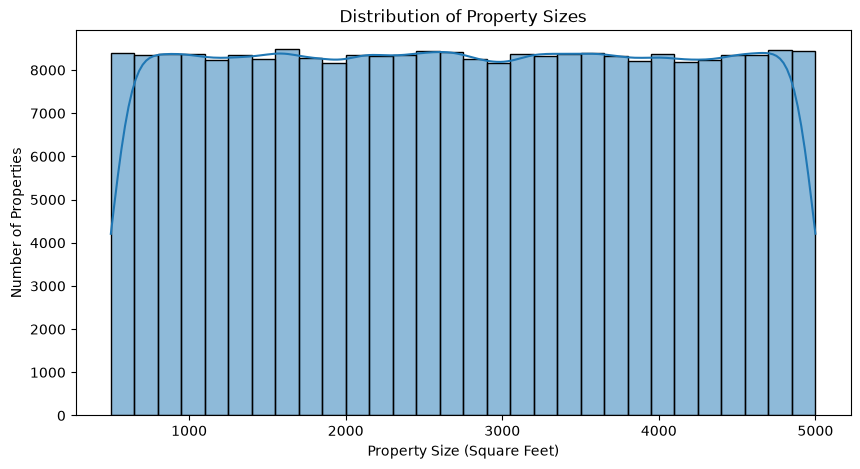

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Size_in_SqFt",
    bins=30,
    kde=True
)

plt.title("Distribution of Property Sizes")
plt.xlabel("Property Size (Square Feet)")
plt.ylabel("Number of Properties")

plt.show()

In [9]:
size_bins = pd.cut(
    df["Size_in_SqFt"],
    bins=10
)

print(
    size_bins.value_counts().sort_index()
)

Size_in_SqFt
(495.5, 950.0]      25173
(950.0, 1400.0]     24956
(1400.0, 1850.0]    25030
(1850.0, 2300.0]    24858
(2300.0, 2750.0]    25197
(2750.0, 3200.0]    24766
(3200.0, 3650.0]    25103
(3650.0, 4100.0]    24918
(4100.0, 4550.0]    24788
(4550.0, 5000.0]    25211
Name: count, dtype: int64


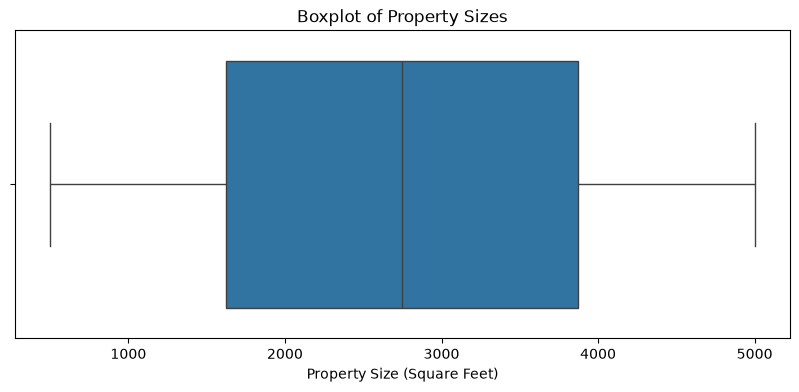

In [10]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["Size_in_SqFt"]
)

plt.title("Boxplot of Property Sizes")
plt.xlabel("Property Size (Square Feet)")

plt.show()

"The distribution of property sizes shows how residential properties are spread across different area ranges. The histogram helps identify the most common property sizes, while the boxplot helps understand the spread and potential outliers."

3 – How does Price per SqFt vary by Property Type?

In [12]:
df["Property_Type"].value_counts()

Property_Type
Villa                83744
Independent House    83300
Apartment            82956
Name: count, dtype: int64

In [15]:
avg_price_type = df.groupby(
    "Property_Type"
)["Price_per_SqFt"].mean().reset_index()

avg_price_type.columns = [
    "Property_Type",
    "Average_Price_Per_SqFt"
]

print(avg_price_type)

       Property_Type  Average_Price_Per_SqFt
0          Apartment                0.130533
1  Independent House                0.131058
2              Villa                0.130317


In [16]:
median_price_type = df.groupby(
    "Property_Type"
)["Price_per_SqFt"].median().reset_index()

median_price_type.columns = [
    "Property_Type",
    "Median_Price_Per_SqFt"
]

print(median_price_type)

       Property_Type  Median_Price_Per_SqFt
0          Apartment                   0.09
1  Independent House                   0.09
2              Villa                   0.09


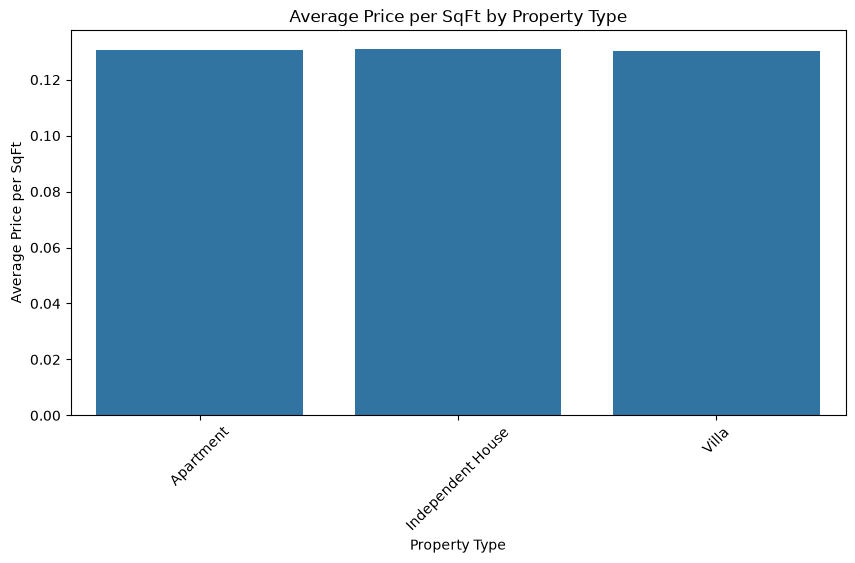

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=avg_price_type,
    x="Property_Type",
    y="Average_Price_Per_SqFt"
)

plt.title("Average Price per SqFt by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price per SqFt")

plt.xticks(rotation=45)

plt.show()

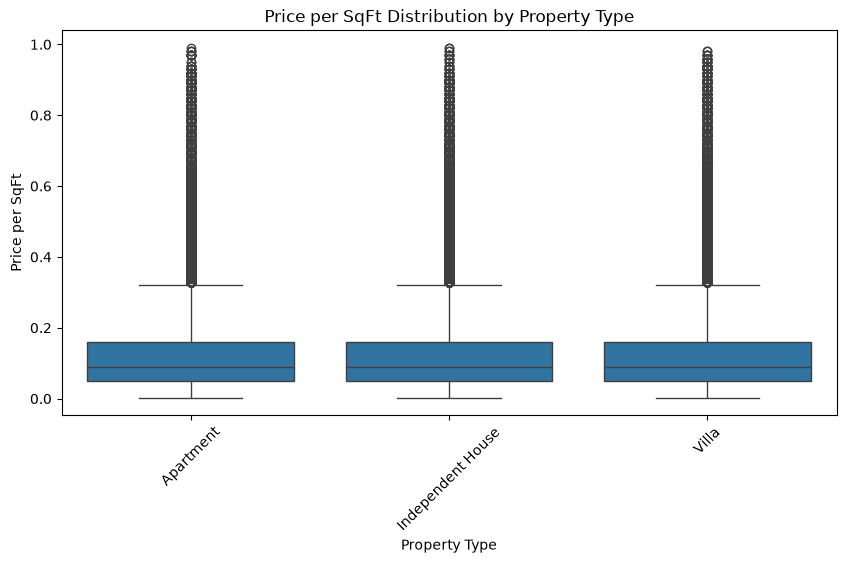

In [19]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df[df["Price_per_SqFt"] > 0],
    x="Property_Type",
    y="Price_per_SqFt"
)

plt.title("Price per SqFt Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price per SqFt")

plt.xticks(rotation=45)

plt.show()

"The analysis compares the average and median price per square foot across different property types. The bar chart shows the average price for each category, while the boxplot highlights the variation and potential outliers. This helps investors compare property types based on their price per square foot."

4 – Is there a relationship between Property Size and Property Price?

In [21]:
correlation = df["Size_in_SqFt"].corr(
    df["Price_in_Lakhs"]
)

print("Correlation:", correlation)

Correlation: -0.002528546792538909


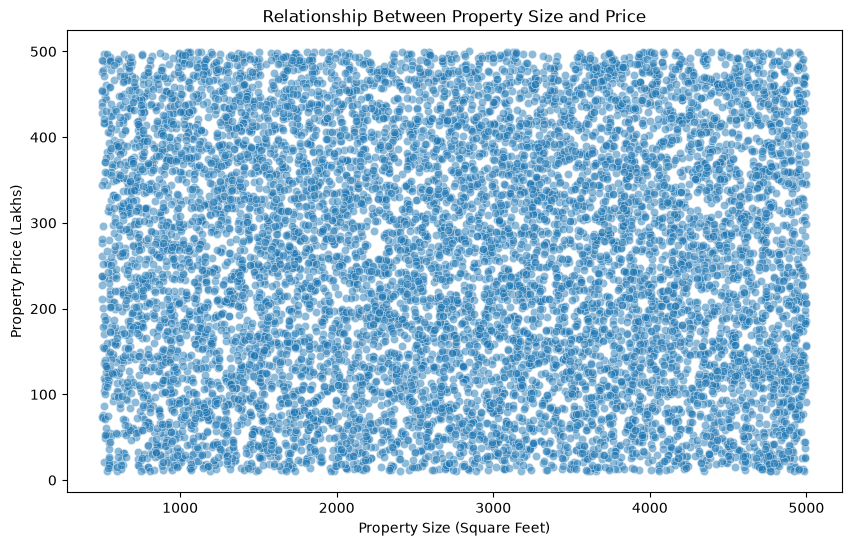

In [22]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.5
)

plt.title("Relationship Between Property Size and Price")
plt.xlabel("Property Size (Square Feet)")
plt.ylabel("Property Price (Lakhs)")

plt.show()

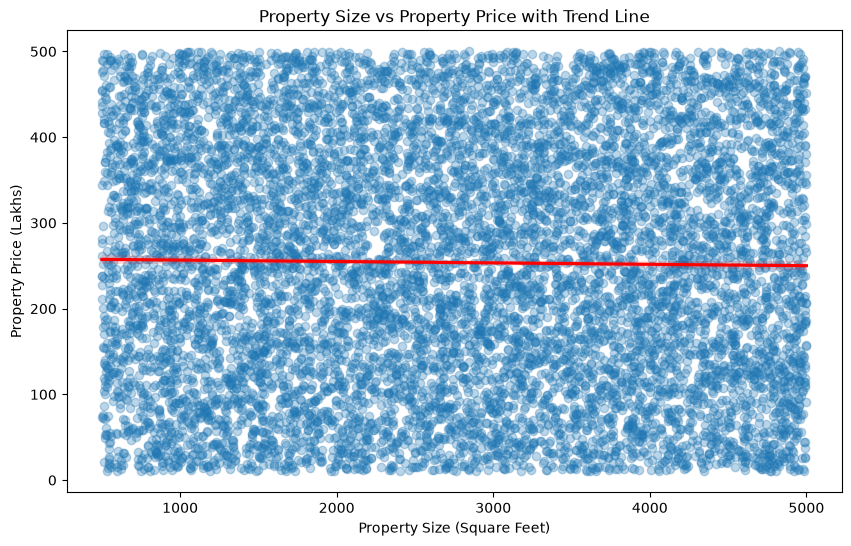

In [23]:
sample_df = df.sample(10000, random_state=42)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=sample_df,
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Property Size vs Property Price with Trend Line")
plt.xlabel("Property Size (Square Feet)")
plt.ylabel("Property Price (Lakhs)")

plt.show()

In [24]:
df["Size_Category"] = pd.cut(
    df["Size_in_SqFt"],
    bins=[0, 500, 1000, 1500, 2000, 3000, float("inf")],
    labels=[
        "Below 500",
        "500-1000",
        "1000-1500",
        "1500-2000",
        "2000-3000",
        "Above 3000"
    ]
)

In [25]:
size_price = df.groupby(
    "Size_Category",
    observed=False
)["Price_in_Lakhs"].mean().reset_index()

print(size_price)

  Size_Category  Price_in_Lakhs
0     Below 500      260.345088
1      500-1000      255.942204
2     1000-1500      255.644476
3     1500-2000      254.229250
4     2000-3000      254.030116
5    Above 3000      254.347745


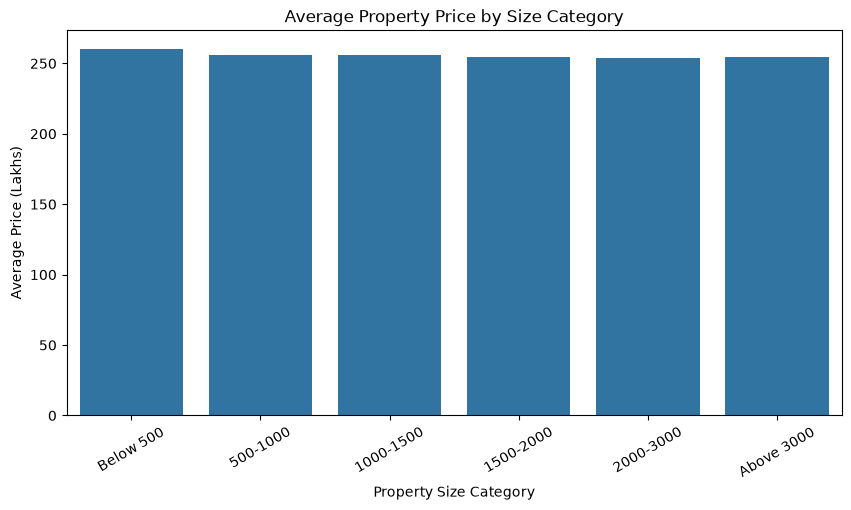

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=size_price,
    x="Size_Category",
    y="Price_in_Lakhs"
)

plt.title("Average Property Price by Size Category")
plt.xlabel("Property Size Category")
plt.ylabel("Average Price (Lakhs)")

plt.xticks(rotation=30)

plt.show()

"The analysis examines the relationship between property size and property price. A scatter plot is used to visualize how prices vary with increasing property area. Correlation analysis helps measure the strength and direction of the linear relationship. The size-category comparison provides additional insight into average property prices across different area groups."

5 – Are there any outliers in Price per SqFt or Property Size

In [27]:
def detect_outliers(column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Total Outliers:", len(outliers))

    return outliers

In [28]:
size_outliers = detect_outliers("Size_in_SqFt")

Column: Size_in_SqFt
Q1: 1623.0
Q3: 3874.0
IQR: 2251.0
Lower Limit: -1753.5
Upper Limit: 7250.5
Total Outliers: 0


In [29]:
valid_price_df = df[df["Price_per_SqFt"] > 0].copy()

Q1 = valid_price_df["Price_per_SqFt"].quantile(0.25)
Q3 = valid_price_df["Price_per_SqFt"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

sqft_outliers = valid_price_df[
    (valid_price_df["Price_per_SqFt"] < lower_limit) |
    (valid_price_df["Price_per_SqFt"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Price per SqFt Outliers:", len(sqft_outliers))

Q1: 0.05
Q3: 0.16
IQR: 0.11
Lower Limit: -0.115
Upper Limit: 0.325
Price per SqFt Outliers: 20020


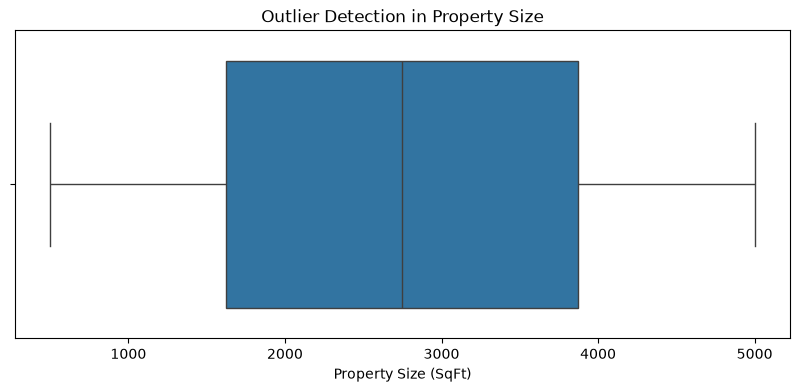

In [30]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Size_in_SqFt"])

plt.title("Outlier Detection in Property Size")
plt.xlabel("Property Size (SqFt)")

plt.show()

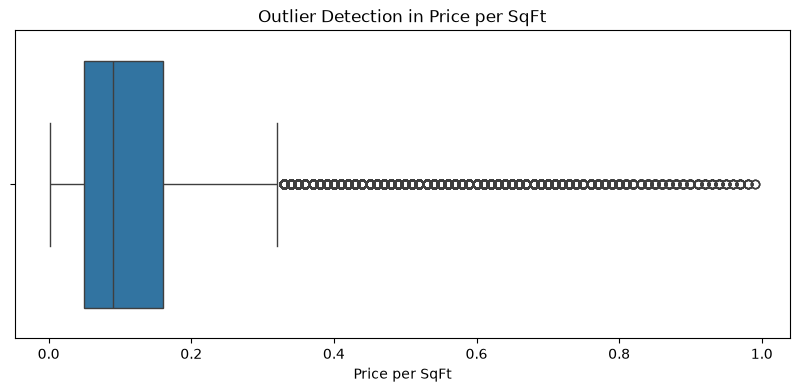

In [31]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=valid_price_df["Price_per_SqFt"]
)

plt.title("Outlier Detection in Price per SqFt")
plt.xlabel("Price per SqFt")


plt.show()

In [32]:
sqft_outliers[
    [
        "City",
        "Property_Type",
        "Size_in_SqFt",
        "Price_in_Lakhs",
        "Price_per_SqFt"
    ]
].head(10)

,City,Property_Type,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt
10,Warangal,Independent House,665,324.24,0.49
20,Noida,Independent House,1270,475.78,0.37
46,Chennai,Villa,641,300.29,0.47
49,Bilaspur,Villa,733,438.74,0.60
51,Haridwar,Independent House,556,308.46,0.55
53,Ranchi,Villa,855,335.30,0.39
57,Jodhpur,Villa,581,457.94,0.79
61,Chennai,Villa,1106,421.32,0.38
65,Bhopal,Apartment,890,439.52,0.49
67,Indore,Apartment,502,486.68,0.97


"The IQR method was used to identify potential outliers in property size and price per square foot. No outliers were detected in property size, whereas price per square foot contained several potential outliers. These records require further investigation because unusually high property rates may represent genuine premium properties."

# Location-based Analysis

6. What is the average price per sq ft by state?

In [37]:
avg_price_state = df.groupby("State")[
    "Price_per_SqFt"
].mean().reset_index()

avg_price_state.columns = [
    "State",
    "Average_Price_Per_SqFt"
]

print(avg_price_state)

             State  Average_Price_Per_SqFt
0   Andhra Pradesh                0.132077
1            Assam                0.130862
2            Bihar                0.130557
3     Chhattisgarh                0.130283
4            Delhi                0.129513
5          Gujarat                0.131037
6          Haryana                0.130729
7        Jharkhand                0.129798
8        Karnataka                0.132571
9           Kerala                0.129884
10  Madhya Pradesh                0.130753
11     Maharashtra                0.130741
12          Odisha                0.130363
13          Punjab                0.129348
14       Rajasthan                0.129374
15      Tamil Nadu                0.131404
16       Telangana                0.130991
17   Uttar Pradesh                0.131462
18     Uttarakhand                0.130283
19     West Bengal                0.130682


In [38]:
avg_price_state = avg_price_state.sort_values(
    by="Average_Price_Per_SqFt",
    ascending=False
)

print(avg_price_state)

             State  Average_Price_Per_SqFt
8        Karnataka                0.132571
0   Andhra Pradesh                0.132077
17   Uttar Pradesh                0.131462
15      Tamil Nadu                0.131404
5          Gujarat                0.131037
16       Telangana                0.130991
1            Assam                0.130862
10  Madhya Pradesh                0.130753
11     Maharashtra                0.130741
6          Haryana                0.130729
19     West Bengal                0.130682
2            Bihar                0.130557
12          Odisha                0.130363
18     Uttarakhand                0.130283
3     Chhattisgarh                0.130283
9           Kerala                0.129884
7        Jharkhand                0.129798
4            Delhi                0.129513
14       Rajasthan                0.129374
13          Punjab                0.129348


In [39]:
highest_state = avg_price_state.iloc[0]

lowest_state = avg_price_state.iloc[-1]

print("Highest Average Price State:")
print(highest_state)

print("\nLowest Average Price State:")
print(lowest_state)

Highest Average Price State:
State                     Karnataka
Average_Price_Per_SqFt     0.132571
Name: 8, dtype: object

Lowest Average Price State:
State                       Punjab
Average_Price_Per_SqFt    0.129348
Name: 13, dtype: object


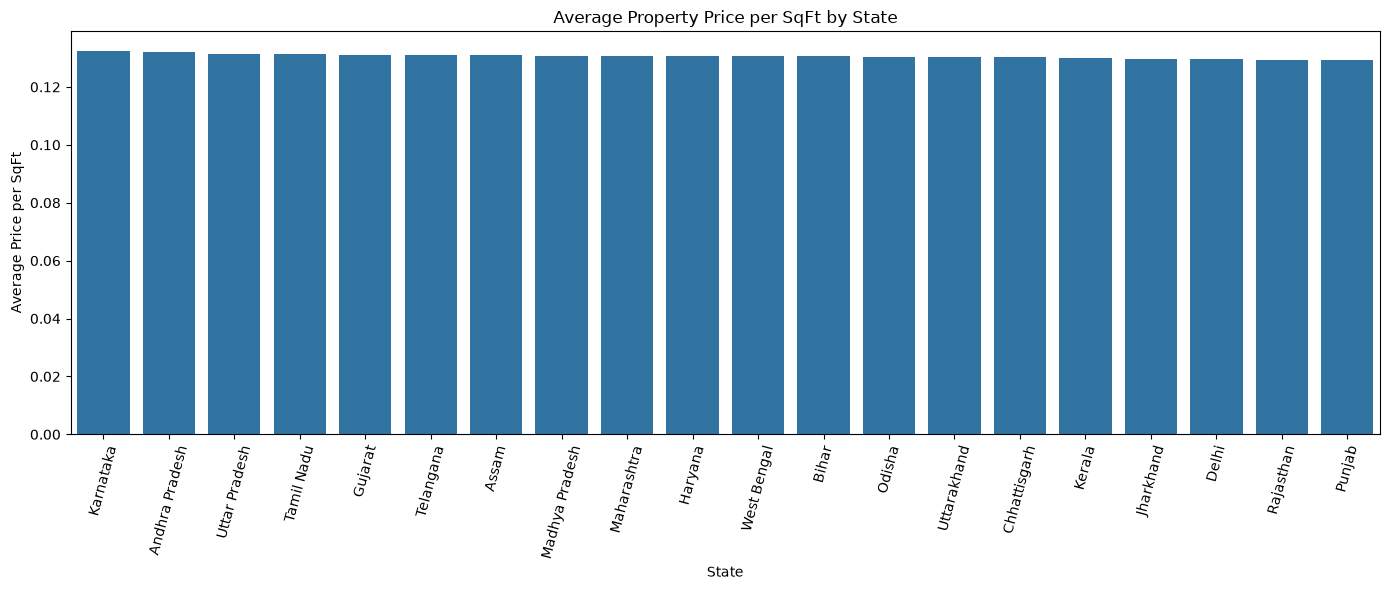

In [40]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=avg_price_state,
    x="State",
    y="Average_Price_Per_SqFt"
)

plt.title("Average Property Price per SqFt by State")
plt.xlabel("State")
plt.ylabel("Average Price per SqFt")

plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

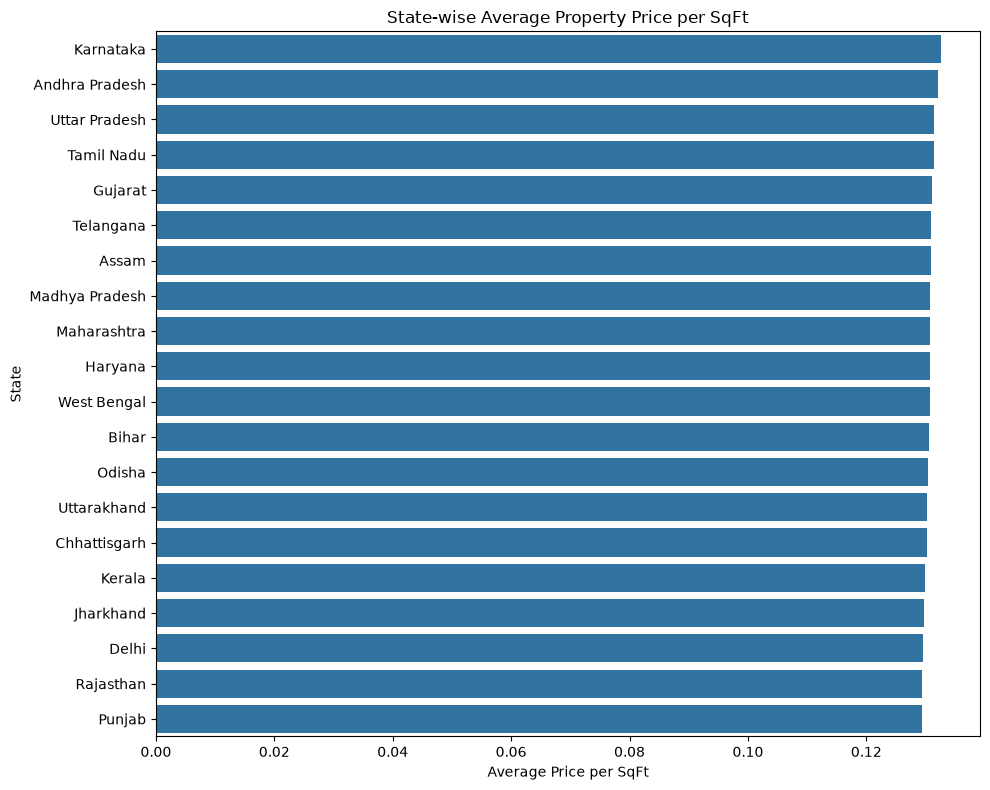

In [41]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=avg_price_state,
    y="State",
    x="Average_Price_Per_SqFt"
)

plt.title("State-wise Average Property Price per SqFt")
plt.xlabel("Average Price per SqFt")
plt.ylabel("State")

plt.tight_layout()
plt.show()

"The state-wise analysis compares average property prices per square foot across different states. Grouping and sorting the data helps identify states with relatively higher and lower property rates. This analysis helps investors understand geographical differences in real estate pricing."

7 – What is the average property price by city?

In [42]:
avg_price_city = df.groupby("City")[
    "Price_in_Lakhs"
].mean().reset_index()

avg_price_city.columns = [
    "City",
    "Average_Property_Price"
]

print(avg_price_city)

              City  Average_Property_Price
0        Ahmedabad              253.586827
1         Amritsar              252.429802
2        Bangalore              258.456639
3           Bhopal              256.498896
4      Bhubaneswar              254.902173
5         Bilaspur              251.879267
6          Chennai              256.830172
7       Coimbatore              256.504745
8          Cuttack              250.786672
9         Dehradun              256.890115
10        Durgapur              254.100152
11          Dwarka              253.454299
12       Faridabad              254.862393
13            Gaya              257.053391
14         Gurgaon              254.027549
15        Guwahati              252.992710
16        Haridwar              252.476004
17       Hyderabad              256.594051
18          Indore              255.413825
19          Jaipur              255.246241
20      Jamshedpur              252.626185
21         Jodhpur              253.947906
22         

In [43]:
avg_price_city = avg_price_city.sort_values(
    by="Average_Property_Price",
    ascending=False
)

print(avg_price_city)

              City  Average_Property_Price
2        Bangalore              258.456639
37           Surat              258.080467
22           Kochi              257.415221
13            Gaya              257.053391
26       Mangalore              256.920925
9         Dehradun              256.890115
28          Mysore              256.848172
6          Chennai              256.830172
17       Hyderabad              256.594051
7       Coimbatore              256.504745
3           Bhopal              256.498896
33            Pune              256.495661
31           Noida              256.287206
24         Lucknow              256.212431
40  Vishakhapatnam              255.772442
29          Nagpur              255.532012
18          Indore              255.413825
19          Jaipur              255.246241
4      Bhubaneswar              254.902173
12       Faridabad              254.862393
39      Vijayawada              254.643766
35          Ranchi              254.624529
41        W

In [44]:
top_10_cities = avg_price_city.head(10)

print(top_10_cities)

          City  Average_Property_Price
2    Bangalore              258.456639
37       Surat              258.080467
22       Kochi              257.415221
13        Gaya              257.053391
26   Mangalore              256.920925
9     Dehradun              256.890115
28      Mysore              256.848172
6      Chennai              256.830172
17   Hyderabad              256.594051
7   Coimbatore              256.504745


In [45]:
bottom_10_cities = avg_price_city.tail(10)

print(bottom_10_cities)

          City  Average_Property_Price
32       Patna              252.794673
20  Jamshedpur              252.626185
36     Silchar              252.576160
16    Haridwar              252.476004
1     Amritsar              252.429802
27      Mumbai              252.056633
5     Bilaspur              251.879267
30   New Delhi              251.614296
38  Trivandrum              251.258801
8      Cuttack              250.786672


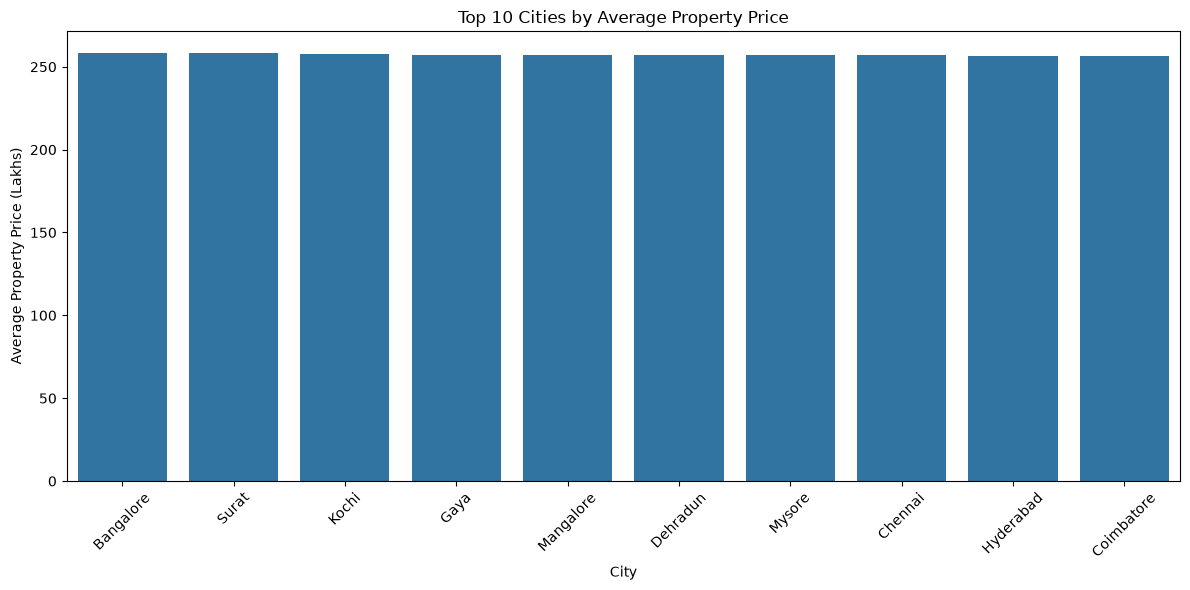

In [46]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_cities,
    x="City",
    y="Average_Property_Price"
)

plt.title("Top 10 Cities by Average Property Price")
plt.xlabel("City")
plt.ylabel("Average Property Price (Lakhs)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

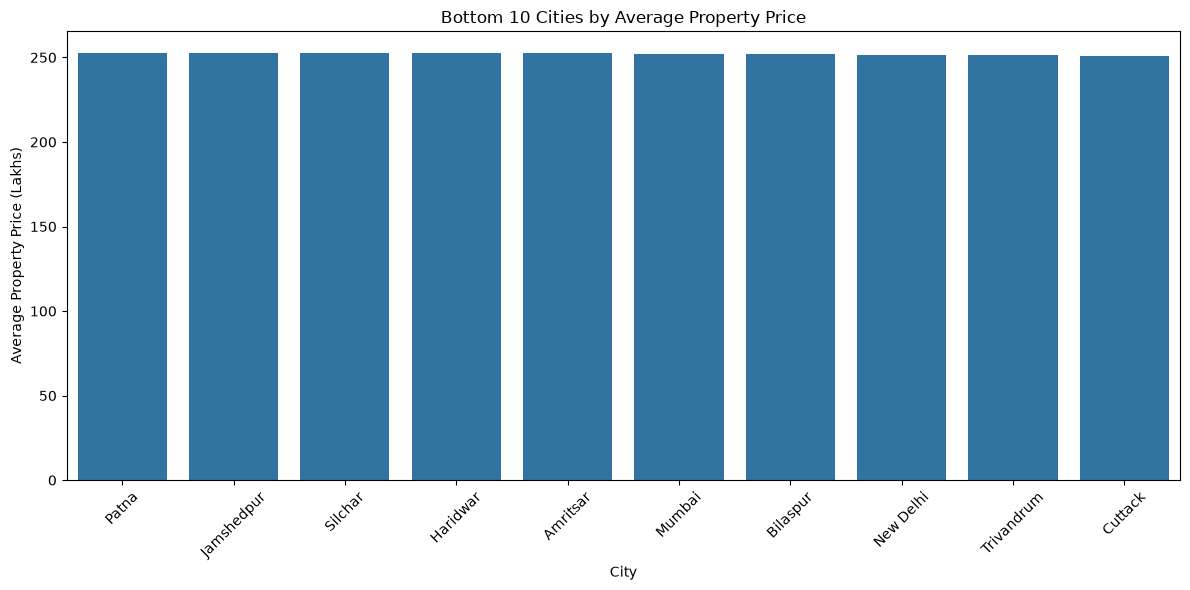

In [47]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=bottom_10_cities,
    x="City",
    y="Average_Property_Price"
)

plt.title("Bottom 10 Cities by Average Property Price")
plt.xlabel("City")
plt.ylabel("Average Property Price (Lakhs)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [48]:
print("Most Expensive City:")

print(avg_price_city.iloc[0])

print("\nLeast Expensive City:")

print(avg_price_city.iloc[-1])

Most Expensive City:
City                       Bangalore
Average_Property_Price    258.456639
Name: 2, dtype: object

Least Expensive City:
City                         Cuttack
Average_Property_Price    250.786672
Name: 8, dtype: object


"The city-wise property price analysis compares average residential property prices across different cities. The analysis identifies cities with higher and lower average property prices. This helps investors understand differences in real estate prices across geographical locations and identify potentially affordable markets."

8 – What is the Median Age of Properties by Locality?

In [49]:
median_age_locality = df.groupby("Locality")[
    "Age_of_Property"
].median().reset_index()

median_age_locality.columns = [
    "Locality",
    "Median_Property_Age"
]

print(median_age_locality)

         Locality  Median_Property_Age
0      Locality_1                 20.0
1     Locality_10                 17.0
2    Locality_100                 19.0
3    Locality_101                 19.0
4    Locality_102                 19.0
..            ...                  ...
495   Locality_95                 19.0
496   Locality_96                 19.0
497   Locality_97                 18.0
498   Locality_98                 18.0
499   Locality_99                 20.0

[500 rows x 2 columns]


In [50]:
median_age_locality = median_age_locality.sort_values(
    by="Median_Property_Age",
    ascending=False
)

print(median_age_locality)

         Locality  Median_Property_Age
470   Locality_72                 21.0
338  Locality_403                 21.0
473   Locality_75                 20.0
31   Locality_127                 20.0
0      Locality_1                 20.0
..            ...                  ...
452   Locality_56                 17.0
34    Locality_13                 17.0
460   Locality_63                 17.0
1     Locality_10                 17.0
382  Locality_443                 16.0

[500 rows x 2 columns]


In [51]:
top_10_old_localities = median_age_locality.head(10)

print(top_10_old_localities)

         Locality  Median_Property_Age
470   Locality_72                 21.0
338  Locality_403                 21.0
473   Locality_75                 20.0
31   Locality_127                 20.0
0      Locality_1                 20.0
499   Locality_99                 20.0
443  Locality_499                 20.0
447   Locality_51                 20.0
435  Locality_491                 20.0
416  Locality_474                 20.0


In [52]:
top_10_new_localities = median_age_locality.tail(10)

print(top_10_new_localities)

         Locality  Median_Property_Age
239  Locality_314                 17.0
273  Locality_345                 17.0
457   Locality_60                 17.0
251  Locality_325                 17.0
237  Locality_312                 17.0
452   Locality_56                 17.0
34    Locality_13                 17.0
460   Locality_63                 17.0
1     Locality_10                 17.0
382  Locality_443                 16.0


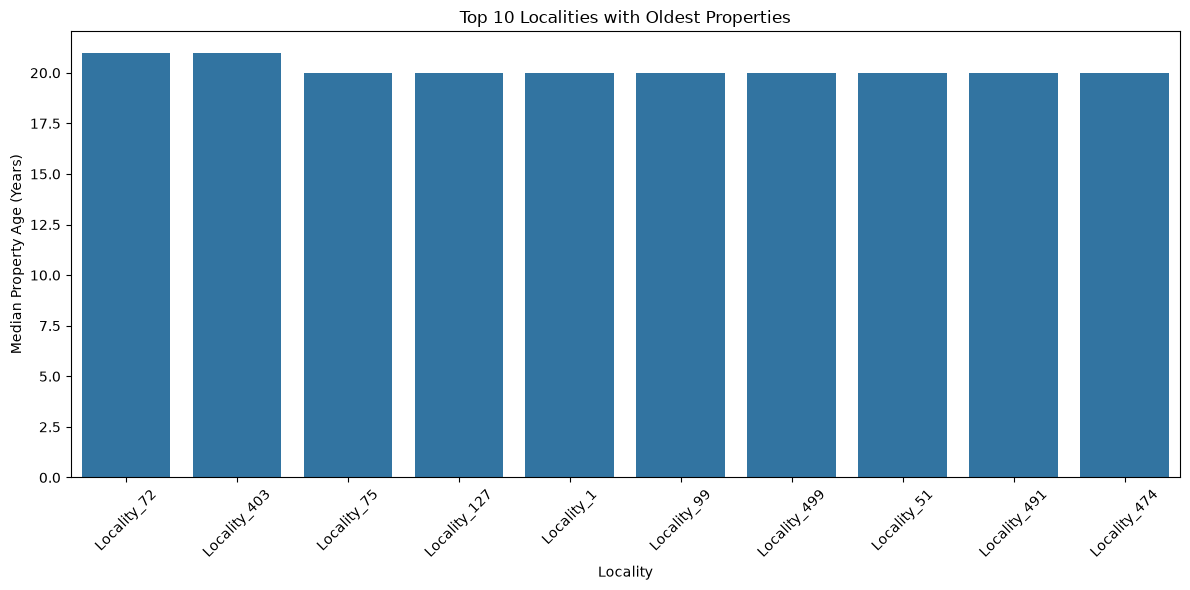

In [53]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_old_localities,
    x="Locality",
    y="Median_Property_Age"
)

plt.title("Top 10 Localities with Oldest Properties")
plt.xlabel("Locality")
plt.ylabel("Median Property Age (Years)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

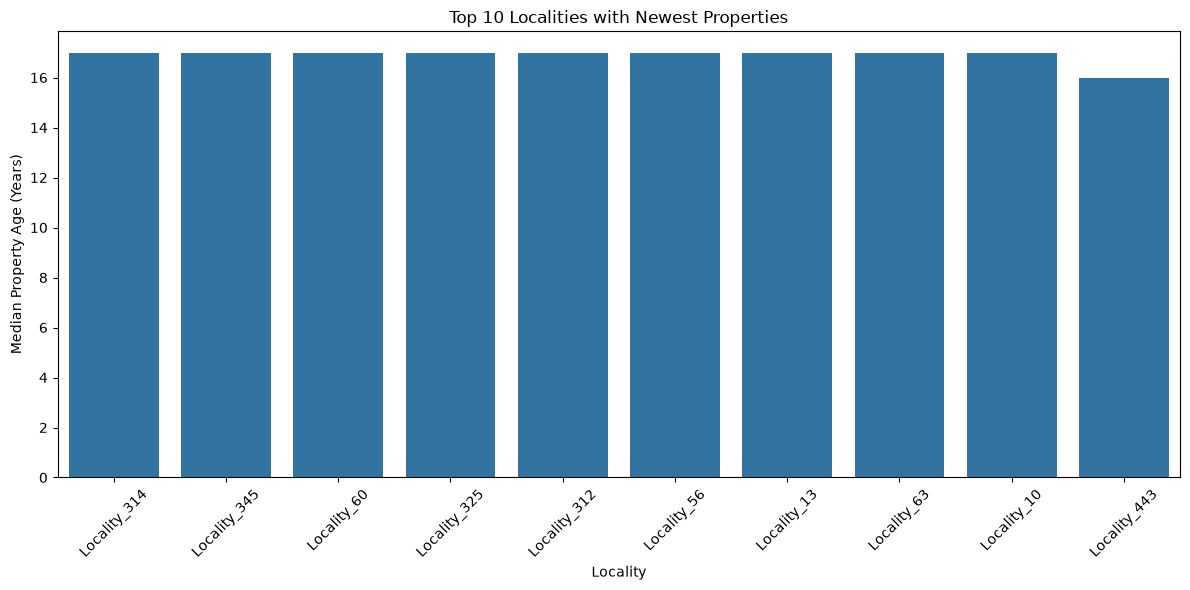

In [54]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_new_localities,
    x="Locality",
    y="Median_Property_Age"
)

plt.title("Top 10 Localities with Newest Properties")
plt.xlabel("Locality")
plt.ylabel("Median Property Age (Years)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

"The locality-wise analysis calculates the median age of properties across different neighborhoods. The results help identify localities with relatively older and newer properties. This information can help investors understand the age profile of available housing in different areas."

9 – How is BHK distributed across cities?

In [55]:
df["BHK"].value_counts().sort_index()

BHK
1    50196
2    49815
3    50067
4    49788
5    50134
Name: count, dtype: int64

In [56]:
bhk_city = pd.crosstab(
    df["City"],
    df["BHK"]
)

print(bhk_city)

BHK                1     2     3     4     5
City                                        
Ahmedabad       1264  1267  1272  1258  1350
Amritsar        1284  1239  1234  1224  1240
Bangalore        839   823   802   833   847
Bhopal          1238  1235  1255  1259  1297
Bhubaneswar     1236  1293  1299  1217  1278
Bilaspur        1210  1252  1275  1268  1258
Chennai         1263  1232  1183  1257  1233
Coimbatore      1236  1301  1317  1345  1262
Cuttack         1320  1292  1301  1236  1209
Dehradun        1238  1297  1225  1248  1226
Durgapur        1311  1259  1287  1260  1270
Dwarka          1295  1211  1248  1216  1276
Faridabad       1202  1231  1261  1214  1261
Gaya            1356  1259  1146  1179  1230
Gurgaon         1241  1221  1239  1232  1212
Guwahati        1240  1158  1272  1188  1234
Haridwar        1233  1290  1230  1223  1291
Hyderabad       1190  1312  1256  1271  1244
Indore          1264  1213  1218  1245  1227
Jaipur          1228  1262  1237  1277  1227
Jamshedpur

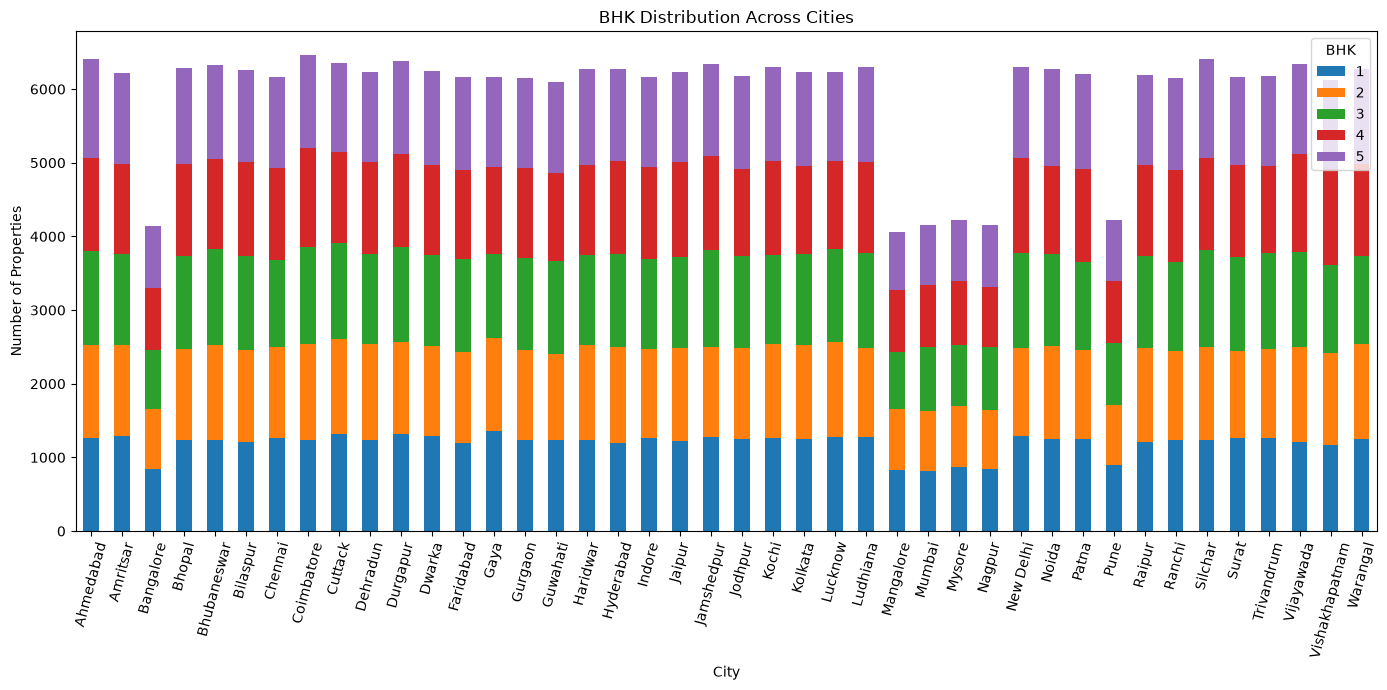

In [57]:
bhk_city.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("BHK Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Number of Properties")

plt.xticks(rotation=75)
plt.legend(title="BHK")

plt.tight_layout()
plt.show()

In [58]:
bhk_percentage = pd.crosstab(
    df["City"],
    df["BHK"],
    normalize="index"
) * 100

print(bhk_percentage.round(2))

BHK                 1      2      3      4      5
City                                             
Ahmedabad       19.72  19.76  19.84  19.62  21.06
Amritsar        20.64  19.92  19.84  19.68  19.93
Bangalore       20.25  19.86  19.35  20.10  20.44
Bhopal          19.70  19.65  19.97  20.04  20.64
Bhubaneswar     19.55  20.45  20.54  19.25  20.21
Bilaspur        19.32  19.99  20.36  20.25  20.09
Chennai         20.48  19.97  19.18  20.38  19.99
Coimbatore      19.13  20.14  20.38  20.82  19.53
Cuttack         20.76  20.32  20.46  19.44  19.02
Dehradun        19.86  20.81  19.65  20.02  19.67
Durgapur        20.53  19.71  20.15  19.73  19.88
Dwarka          20.73  19.39  19.98  19.47  20.43
Faridabad       19.48  19.95  20.44  19.68  20.44
Gaya            21.98  20.41  18.57  19.11  19.94
Gurgaon         20.20  19.87  20.16  20.05  19.72
Guwahati        20.35  19.01  20.88  19.50  20.26
Haridwar        19.67  20.58  19.63  19.51  20.60
Hyderabad       18.97  20.92  20.02  20.26  19.83


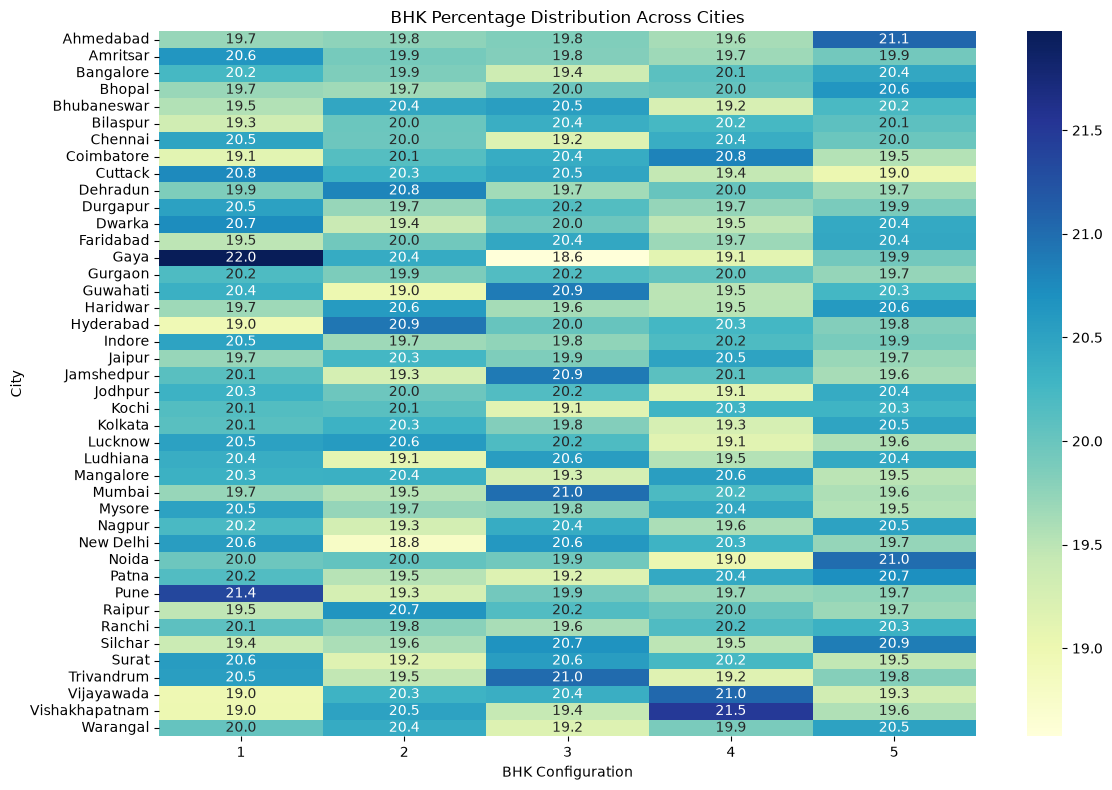

In [59]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    bhk_percentage,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("BHK Percentage Distribution Across Cities")
plt.xlabel("BHK Configuration")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [60]:
most_common_bhk = bhk_city.idxmax(axis=1)

print("Most Common BHK by City:")

print(most_common_bhk)

Most Common BHK by City:
City
Ahmedabad         5
Amritsar          1
Bangalore         5
Bhopal            5
Bhubaneswar       3
Bilaspur          3
Chennai           1
Coimbatore        4
Cuttack           1
Dehradun          2
Durgapur          1
Dwarka            1
Faridabad         3
Gaya              1
Gurgaon           1
Guwahati          3
Haridwar          5
Hyderabad         2
Indore            1
Jaipur            4
Jamshedpur        3
Jodhpur           5
Kochi             4
Kolkata           5
Lucknow           2
Ludhiana          3
Mangalore         4
Mumbai            3
Mysore            1
Nagpur            5
New Delhi         3
Noida             5
Patna             5
Pune              1
Raipur            2
Ranchi            5
Silchar           5
Surat             1
Trivandrum        3
Vijayawada        4
Vishakhapatnam    4
Warangal          5
dtype: int64


"The BHK distribution analysis examines the availability of different bedroom configurations across cities. A frequency table and stacked bar chart are used to compare property counts, while a percentage-based heatmap highlights the relative distribution of BHK configurations in each city. This analysis helps understand housing preferences and property availability across different cities."

10 – What are the Price Trends for the Top 5 Most Expensive Localities?

In [61]:
avg_price_locality = df.groupby("Locality")[
    "Price_in_Lakhs"
].mean().reset_index()

avg_price_locality.columns = [
    "Locality",
    "Average_Property_Price"
]

print(avg_price_locality.head())

       Locality  Average_Property_Price
0    Locality_1              259.106765
1   Locality_10              252.026784
2  Locality_100              254.670586
3  Locality_101              249.904669
4  Locality_102              255.008911


In [62]:
top_5_localities = avg_price_locality.sort_values(
    by="Average_Property_Price",
    ascending=False
).head(5)

print(top_5_localities)

         Locality  Average_Property_Price
328  Locality_395              275.425987
296  Locality_366              273.411996
441  Locality_497              269.995540
290  Locality_360              269.806792
116  Locality_203              269.033716


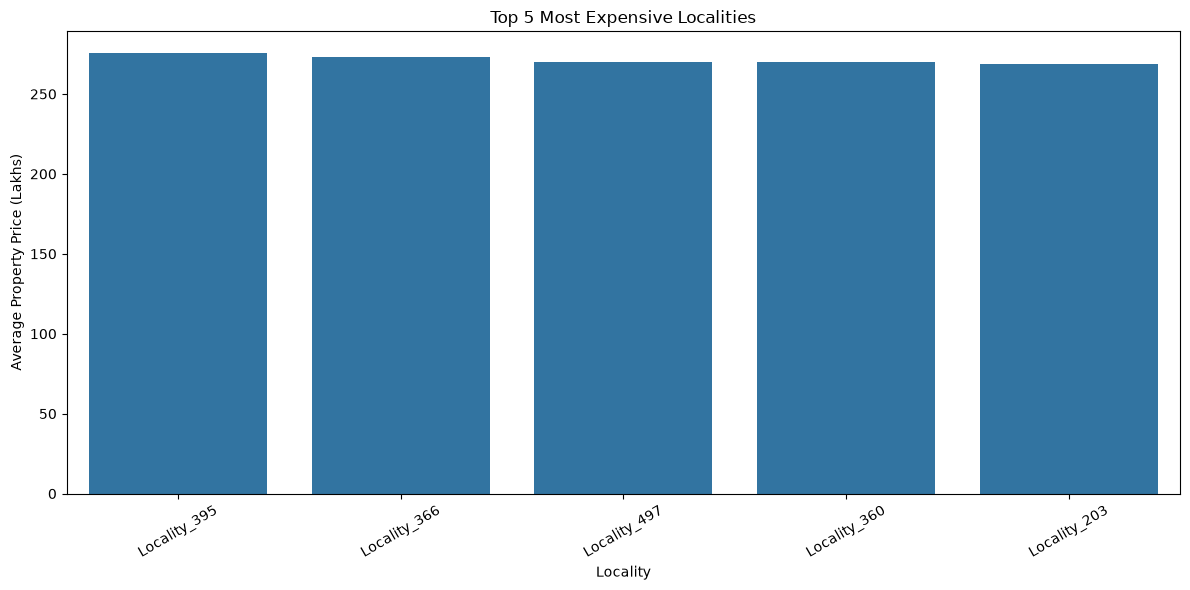

In [63]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_5_localities,
    x="Locality",
    y="Average_Property_Price"
)

plt.title("Top 5 Most Expensive Localities")
plt.xlabel("Locality")
plt.ylabel("Average Property Price (Lakhs)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

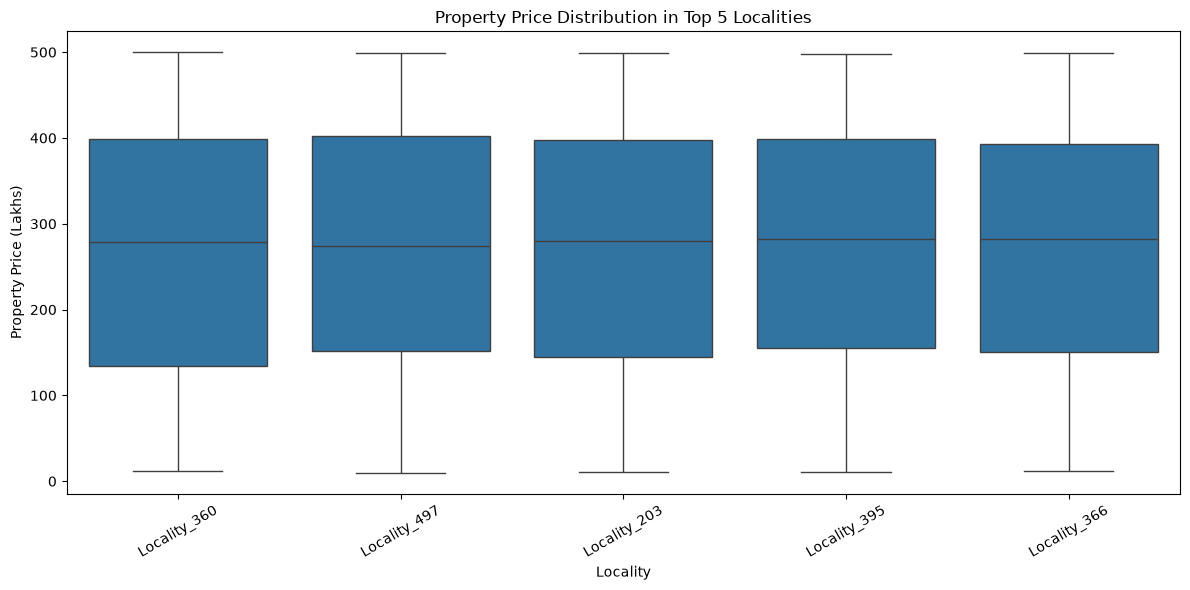

In [64]:
top_5_names = top_5_localities["Locality"].tolist()

top_5_data = df[
    df["Locality"].isin(top_5_names)
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=top_5_data,
    x="Locality",
    y="Price_in_Lakhs"
)

plt.title("Property Price Distribution in Top 5 Localities")
plt.xlabel("Locality")
plt.ylabel("Property Price (Lakhs)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [65]:
most_expensive = top_5_localities.iloc[0]

print("Most Expensive Locality:")
print("Locality:", most_expensive["Locality"])
print(
    "Average Price:",
    round(most_expensive["Average_Property_Price"], 2),
    "Lakhs"
)

Most Expensive Locality:
Locality: Locality_395
Average Price: 275.43 Lakhs


"The analysis identifies the five most expensive localities based on their average property prices. A bar chart is used to compare average prices, while a boxplot shows the variation in property prices within each locality. This analysis helps investors identify relatively expensive residential areas."

# Feature Relationship & Correlation

11.How are numeric features correlated with each other?

In [66]:
# Select numerical columns

numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)

print(numeric_df.columns.tolist())

['ID', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals']


In [67]:
numeric_df = numeric_df.drop(
    columns=["ID"],
    errors="ignore"
)

print(numeric_df.head())

   BHK  Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  Year_Built  Floor_No  \
0    1          4740          489.76            0.10        1990        22   
1    3          2364          195.52            0.08        2008        21   
2    2          3642          183.79            0.05        1997        19   
3    2          2741          300.29            0.11        1991        21   
4    4          4823          182.90            0.04        2002         3   

   Total_Floors  Age_of_Property  Nearby_Schools  Nearby_Hospitals  
0             1               35              10                 3  
1            20               17               8                 1  
2            27               28               9                 8  
3            26               34               5                 7  
4             2               23               4                 9  


In [68]:
correlation_matrix = numeric_df.corr()

print(correlation_matrix)

                       BHK  Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  \
BHK               1.000000     -0.001033       -0.000980        0.001186   
Size_in_SqFt     -0.001033      1.000000       -0.002529       -0.614443   
Price_in_Lakhs   -0.000980     -0.002529        1.000000        0.555287   
Price_per_SqFt    0.001186     -0.614443        0.555287        1.000000   
Year_Built        0.000917      0.004135        0.002714       -0.001210   
Floor_No          0.001263     -0.002775       -0.001719       -0.001907   
Total_Floors     -0.002862     -0.003451        0.001283        0.004181   
Age_of_Property  -0.000917     -0.004135       -0.002714        0.001210   
Nearby_Schools   -0.000762      0.001966        0.000155       -0.000089   
Nearby_Hospitals  0.001162     -0.001695       -0.002769       -0.000145   

                  Year_Built  Floor_No  Total_Floors  Age_of_Property  \
BHK                 0.000917  0.001263     -0.002862        -0.000917   
Size_in_SqFt     

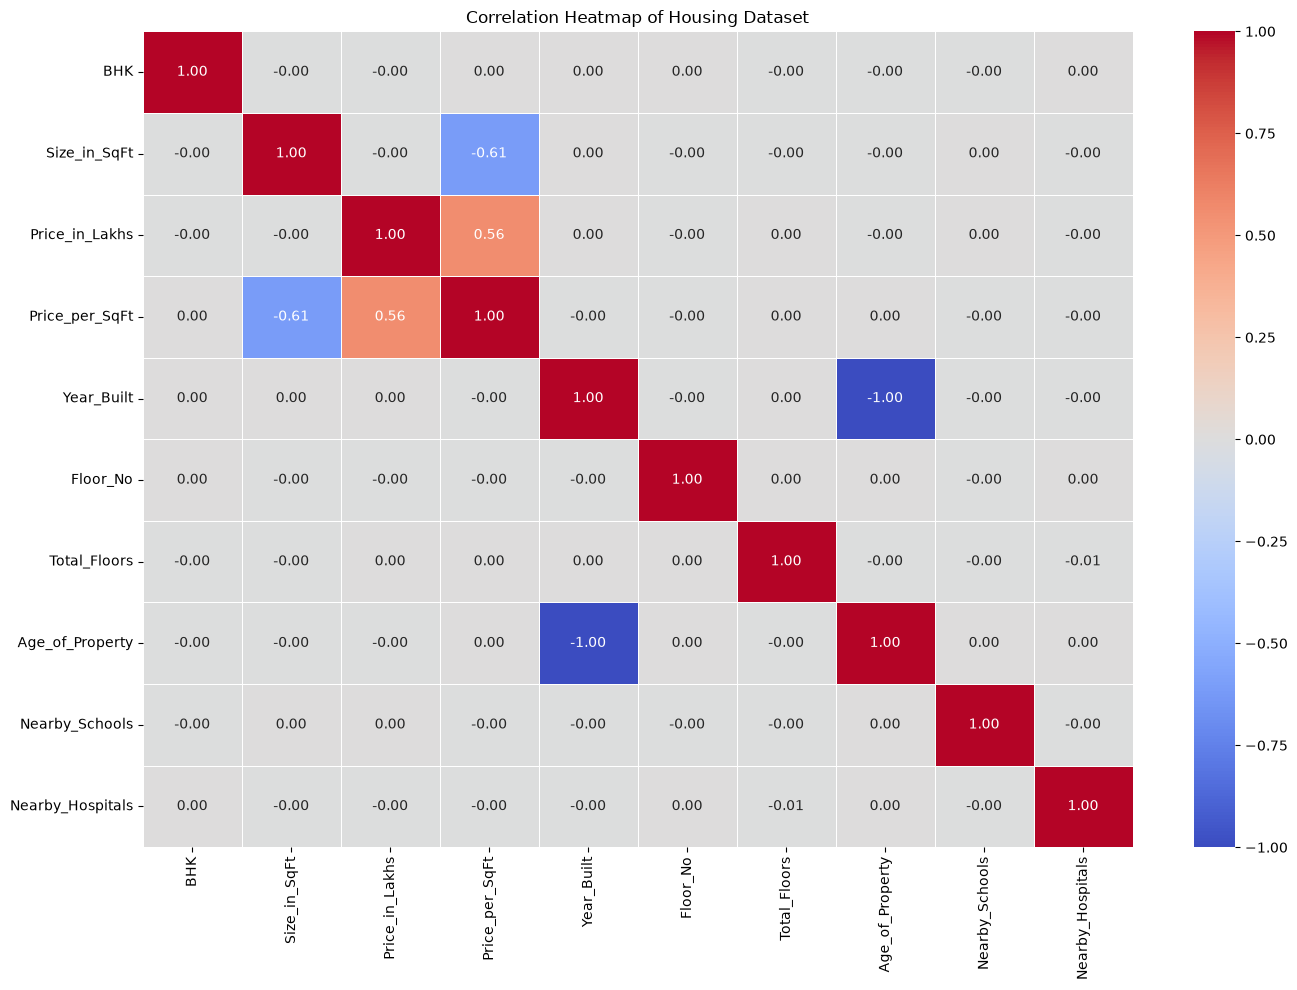

In [69]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Dataset")

plt.tight_layout()
plt.show()

In [70]:
# Get upper triangle of correlation matrix

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Find highly correlated pairs

high_corr = upper_triangle.stack().reset_index()

high_corr.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_corr = high_corr[
    high_corr["Correlation"].abs() >= 0.70
]

high_corr = high_corr.sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print(high_corr)

     Feature_1        Feature_2  Correlation
47  Year_Built  Age_of_Property         -1.0


This displays feature pairs having an absolute correlation of 0.70 or higher.

Important: Some features may be mathematically related. For example, property age is calculated from construction year, so those two columns will have a strong negative correlation. This does not necessarily mean one causes the other.

Also, correlations do not prove causation.

"The correlation analysis examines the relationships between numerical features in the housing dataset. A correlation matrix and heatmap are used to identify positive and negative linear relationships. This helps understand how property prices, property sizes, age and nearby facilities are associated with each other."



12 – How do Nearby Schools relate to Price per SqFt?

In [72]:
print(df["Nearby_Schools"].describe())

print("\nUnique values:")
print(sorted(df["Nearby_Schools"].dropna().unique()))

count    250000.000000
mean          5.499860
std           2.878639
min           1.000000
25%           3.000000
50%           5.000000
75%           8.000000
max          10.000000
Name: Nearby_Schools, dtype: float64

Unique values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [73]:
school_price = df[df["Price_per_SqFt"] > 0].groupby(
    "Nearby_Schools"
)["Price_per_SqFt"].agg(
    ["mean", "median", "count"]
).reset_index()

school_price.columns = [
    "Nearby_Schools",
    "Average_Price_Per_SqFt",
    "Median_Price_Per_SqFt",
    "Property_Count"
]

print(school_price)

   Nearby_Schools  Average_Price_Per_SqFt  Median_Price_Per_SqFt  \
0               1                0.130681                   0.09   
1               2                0.131311                   0.09   
2               3                0.130750                   0.09   
3               4                0.128931                   0.09   
4               5                0.129978                   0.09   
5               6                0.132970                   0.09   
6               7                0.130476                   0.09   
7               8                0.129601                   0.09   
8               9                0.131083                   0.09   
9              10                0.130589                   0.09   

   Property_Count  
0           25360  
1           24851  
2           25045  
3           24739  
4           25023  
5           24824  
6           24808  
7           25290  
8           24823  
9           25237  


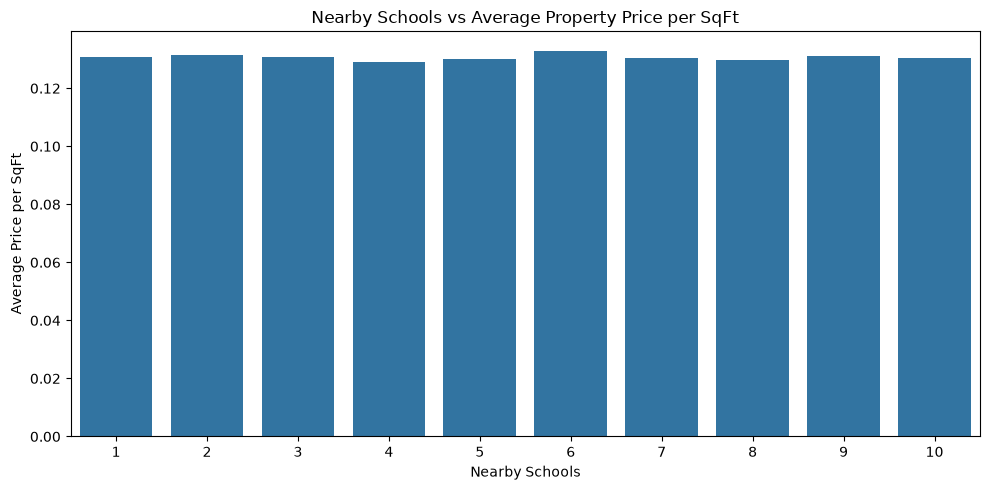

In [74]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=school_price,
    x="Nearby_Schools",
    y="Average_Price_Per_SqFt"
)

plt.title("Nearby Schools vs Average Property Price per SqFt")
plt.xlabel("Nearby Schools")
plt.ylabel("Average Price per SqFt")

plt.tight_layout()
plt.show()

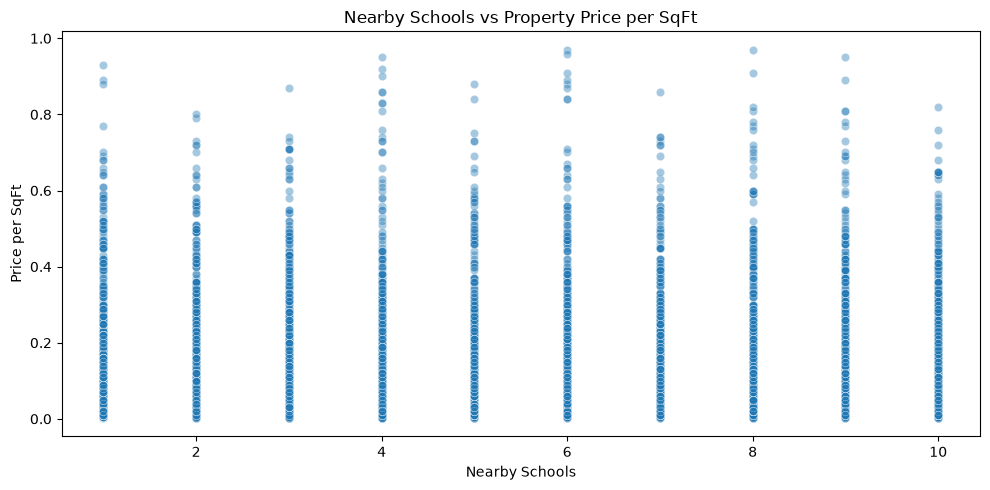

In [75]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df[df["Price_per_SqFt"] > 0].sample(
        10000, random_state=42
    ),
    x="Nearby_Schools",
    y="Price_per_SqFt",
    alpha=0.4
)

plt.title("Nearby Schools vs Property Price per SqFt")
plt.xlabel("Nearby Schools")
plt.ylabel("Price per SqFt")

plt.tight_layout()
plt.show()

In [76]:
school_correlation = df[
    ["Nearby_Schools", "Price_per_SqFt"]
].corr().iloc[0, 1]

print(
    "Correlation between Nearby Schools and Price per SqFt:",
    round(school_correlation, 3)
)

Correlation between Nearby Schools and Price per SqFt: -0.0


"The analysis examines the relationship between nearby schools and property prices per square foot. Average and median price comparisons are used to understand how property prices vary with school availability. Scatter plots and correlation analysis help identify the direction and strength of the relationship."

13 – How do Nearby Hospitals relate to Price per SqFt?

In [77]:
print(df["Nearby_Hospitals"].describe())

print("\nUnique values:")

print(sorted(df["Nearby_Hospitals"].dropna().unique()))

count    250000.000000
mean          5.498016
std           2.871860
min           1.000000
25%           3.000000
50%           5.000000
75%           8.000000
max          10.000000
Name: Nearby_Hospitals, dtype: float64

Unique values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [78]:
hospital_price = df[
    df["Price_per_SqFt"] > 0
].groupby("Nearby_Hospitals")[
    "Price_per_SqFt"
].agg(
    ["mean", "median", "count"]
).reset_index()

hospital_price.columns = [
    "Nearby_Hospitals",
    "Average_Price_Per_SqFt",
    "Median_Price_Per_SqFt",
    "Property_Count"
]

print(hospital_price)

   Nearby_Hospitals  Average_Price_Per_SqFt  Median_Price_Per_SqFt  \
0                 1                0.130247                   0.09   
1                 2                0.130309                   0.09   
2                 3                0.132390                   0.09   
3                 4                0.130022                   0.09   
4                 5                0.129220                   0.09   
5                 6                0.130116                   0.09   
6                 7                0.132638                   0.09   
7                 8                0.131212                   0.09   
8                 9                0.130862                   0.09   
9                10                0.129374                   0.09   

   Property_Count  
0           25075  
1           24960  
2           24834  
3           25168  
4           25102  
5           25082  
6           24887  
7           24891  
8           25014  
9           24987  


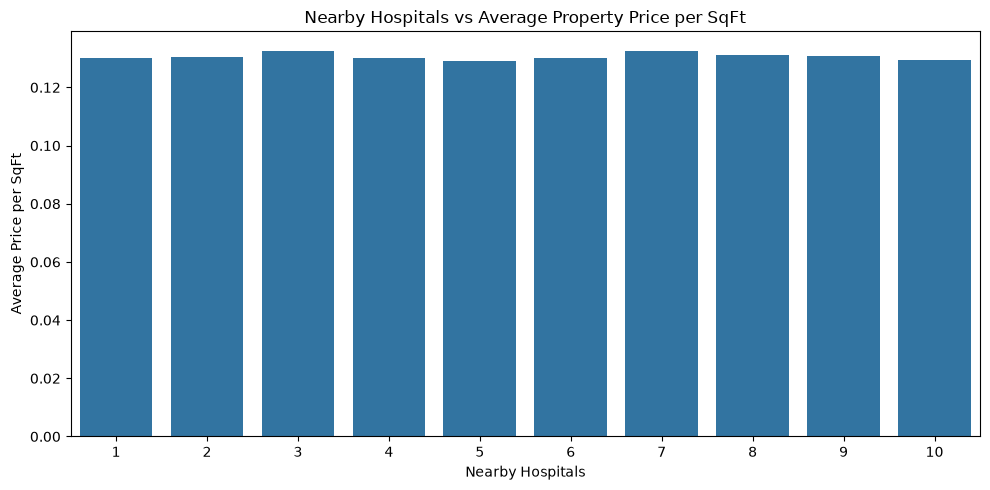

In [79]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=hospital_price,
    x="Nearby_Hospitals",
    y="Average_Price_Per_SqFt"
)

plt.title("Nearby Hospitals vs Average Property Price per SqFt")
plt.xlabel("Nearby Hospitals")
plt.ylabel("Average Price per SqFt")

plt.tight_layout()
plt.show()

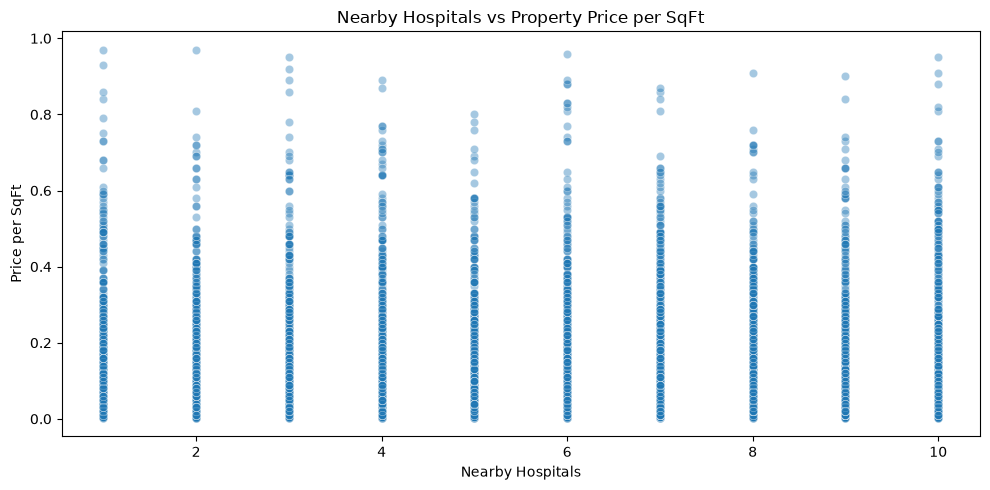

In [80]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df[df["Price_per_SqFt"] > 0].sample(
        10000,
        random_state=42
    ),
    x="Nearby_Hospitals",
    y="Price_per_SqFt",
    alpha=0.4
)

plt.title("Nearby Hospitals vs Property Price per SqFt")
plt.xlabel("Nearby Hospitals")
plt.ylabel("Price per SqFt")

plt.tight_layout()
plt.show()

In [81]:
hospital_correlation = df[
    ["Nearby_Hospitals", "Price_per_SqFt"]
].corr().iloc[0, 1]

print(
    "Correlation between Nearby Hospitals and Price per SqFt:",
    round(hospital_correlation, 3)
)


Correlation between Nearby Hospitals and Price per SqFt: -0.0


How to understand the result?

Correlation	Meaning

Near +1	Strong positive relationship

Near 0	Weak linear relationship

Near -1	Strong negative relationship


Remember: correlation does not prove that hospitals cause property prices to increase.

"The analysis examines the relationship between nearby hospitals and property prices per square foot. Average and median price comparisons are used to understand how property prices vary with hospital availability. Scatter plots and correlation analysis help identify the strength and direction of the relationship."


14 – How does Property Price vary by Furnished Status?

In [82]:
print(df["Furnished_Status"].value_counts())

Furnished_Status
Unfurnished       83408
Semi-Furnished    83374
Furnished         83218
Name: count, dtype: int64


In [83]:
furnished_price = df.groupby(
    "Furnished_Status"
)["Price_in_Lakhs"].agg(
    ["mean", "median", "count"]
).reset_index()

furnished_price.columns = [
    "Furnished_Status",
    "Average_Price",
    "Median_Price",
    "Property_Count"
]

print(furnished_price)

  Furnished_Status  Average_Price  Median_Price  Property_Count
0        Furnished     254.445550       253.555           83218
1   Semi-Furnished     254.334836       253.810           83374
2      Unfurnished     254.979752       254.190           83408


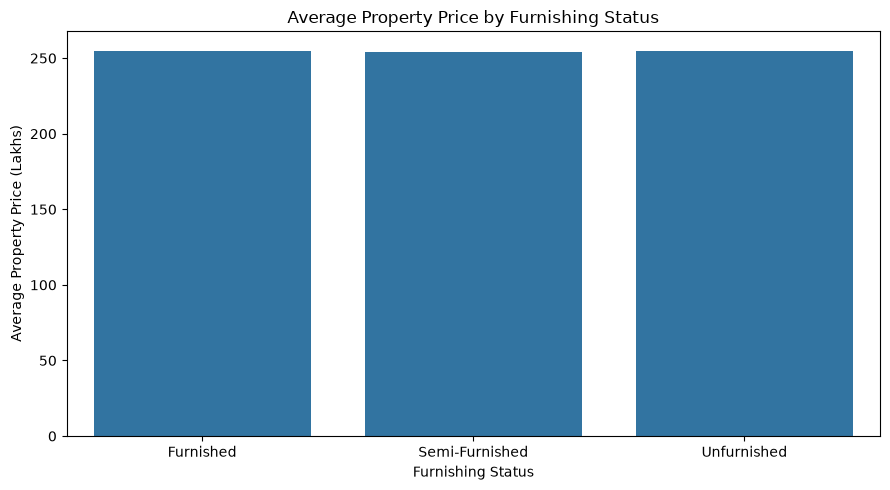

In [84]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=furnished_price,
    x="Furnished_Status",
    y="Average_Price"
)

plt.title("Average Property Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()

plt.show()

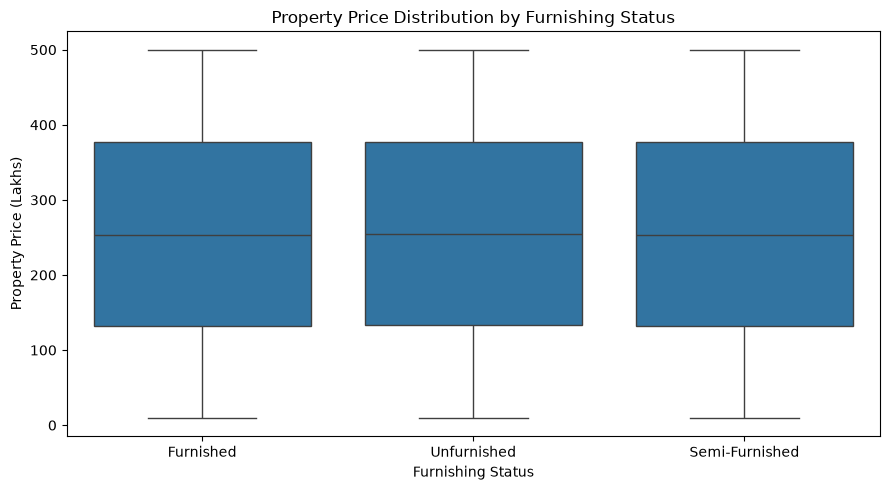

In [85]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Furnished_Status",
    y="Price_in_Lakhs"
)

plt.title("Property Price Distribution by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Property Price (Lakhs)")

plt.tight_layout()
plt.show()

In [86]:
highest_furnished = furnished_price.sort_values(
    by="Average_Price",
    ascending=False
)

print("Furnishing Category with Highest Average Price:")
print(highest_furnished.iloc[0])

Furnishing Category with Highest Average Price:
Furnished_Status    Unfurnished
Average_Price        254.979752
Median_Price             254.19
Property_Count            83408
Name: 2, dtype: object


"The analysis compares residential property prices across different furnishing categories. Average and median prices are calculated for unfurnished, semi-furnished and fully furnished properties. Bar charts and boxplots are used to understand price differences and variations across these categories."

15 – How does Price per SqFt vary by Property Facing Direction?

In [87]:
print(df["Facing"].value_counts())

Facing
West     62757
North    62637
South    62337
East     62269
Name: count, dtype: int64


In [88]:
facing_price = df[
    df["Price_per_SqFt"] > 0
].groupby("Facing")[
    "Price_per_SqFt"
].agg(
    ["mean", "median", "count"]
).reset_index()

facing_price.columns = [
    "Facing",
    "Average_Price_Per_SqFt",
    "Median_Price_Per_SqFt",
    "Property_Count"
]

print(facing_price)

  Facing  Average_Price_Per_SqFt  Median_Price_Per_SqFt  Property_Count
0   East                0.130294                   0.09           62269
1  North                0.130290                   0.09           62637
2  South                0.130495                   0.09           62337
3   West                0.131457                   0.09           62757


In [89]:
facing_price = facing_price.sort_values(
    by="Average_Price_Per_SqFt",
    ascending=False
)

print(facing_price)

  Facing  Average_Price_Per_SqFt  Median_Price_Per_SqFt  Property_Count
3   West                0.131457                   0.09           62757
2  South                0.130495                   0.09           62337
0   East                0.130294                   0.09           62269
1  North                0.130290                   0.09           62637


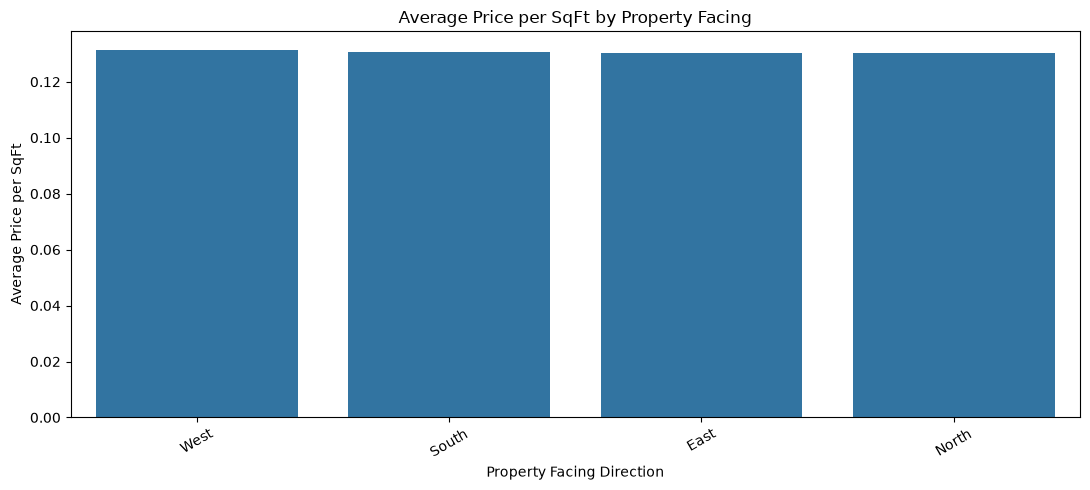

In [90]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=facing_price,
    x="Facing",
    y="Average_Price_Per_SqFt"
)

plt.title("Average Price per SqFt by Property Facing")
plt.xlabel("Property Facing Direction")
plt.ylabel("Average Price per SqFt")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

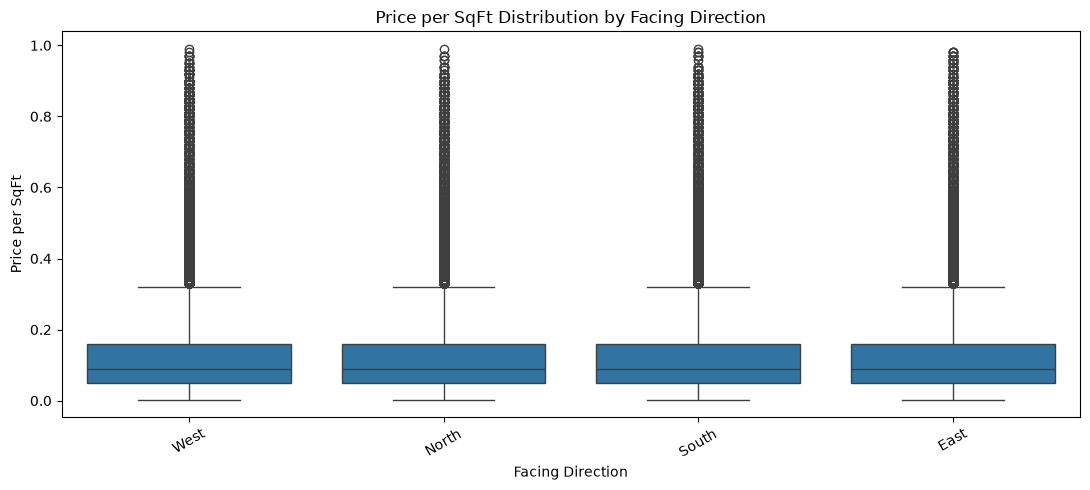

In [91]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df[df["Price_per_SqFt"] > 0],
    x="Facing",
    y="Price_per_SqFt"
)

plt.title("Price per SqFt Distribution by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Price per SqFt")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [92]:
print("Highest Average Price Facing:")

print(facing_price.iloc[0])

print("\nLowest Average Price Facing:")

print(facing_price.iloc[-1])

Highest Average Price Facing:
Facing                        West
Average_Price_Per_SqFt    0.131457
Median_Price_Per_SqFt         0.09
Property_Count               62757
Name: 3, dtype: object

Lowest Average Price Facing:
Facing                      North
Average_Price_Per_SqFt    0.13029
Median_Price_Per_SqFt        0.09
Property_Count              62637
Name: 1, dtype: object


"The analysis compares property prices per square foot across different facing directions. Average and median prices are calculated for each direction. Bar charts and boxplots help identify price differences and variations among properties with different facing directions."

16 – How many properties belong to each Owner Type?

In [93]:
print(df["Owner_Type"].value_counts())

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64


In [94]:
owner_percentage = df["Owner_Type"].value_counts(normalize=True) * 100

print(owner_percentage.round(2))

Owner_Type
Broker     33.39
Owner      33.31
Builder    33.30
Name: proportion, dtype: float64


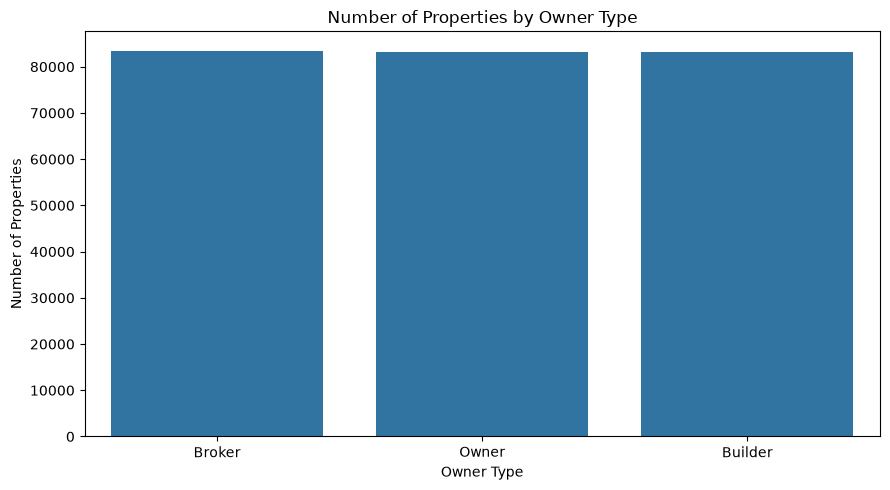

In [95]:
owner_counts = df["Owner_Type"].value_counts().reset_index()

owner_counts.columns = ["Owner_Type", "Property_Count"]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=owner_counts,
    x="Owner_Type",
    y="Property_Count"
)

plt.title("Number of Properties by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

In [96]:
most_common_owner = owner_counts.loc[
    owner_counts["Property_Count"].idxmax()
]

print("Most common owner type:", most_common_owner["Owner_Type"])
print("Number of properties:", most_common_owner["Property_Count"])

Most common owner type: Broker
Number of properties: 83479


The analysis shows the distribution of properties across different owner types. The most common owner type is broker , with 83479 properties. This helps us understand which category contributes the largest number of properties to the dataset.

17 – How many properties are available under each Availability Status?

In [97]:
print(df["Availability_Status"].value_counts())

Availability_Status
Under_Construction    125035
Ready_To_Move         124965
Name: count, dtype: int64


In [98]:
availability_percentage = (
    df["Availability_Status"].value_counts(normalize=True) * 100
)

print(availability_percentage.round(2))

Availability_Status
Under_Construction    50.01
Ready_To_Move         49.99
Name: proportion, dtype: float64


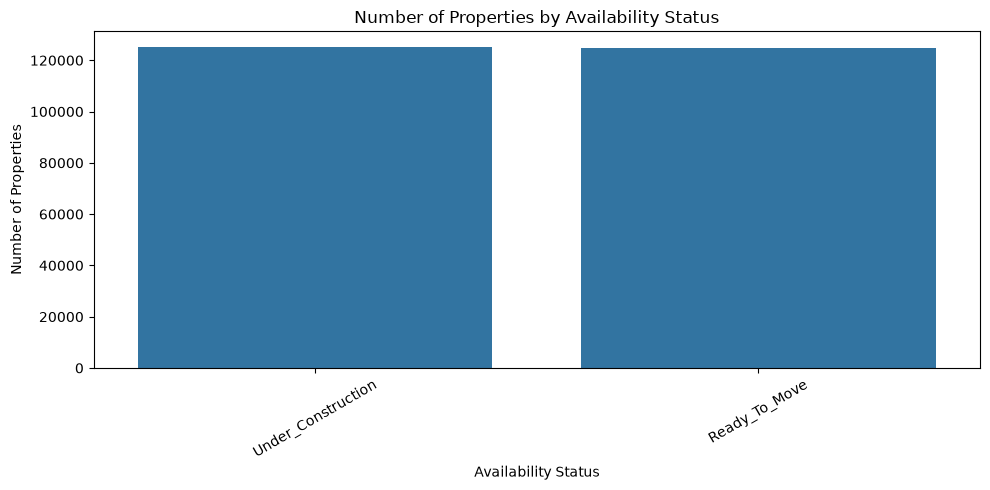

In [ ]:
availability_counts = (
    df["Availability_Status"]
    .value_counts()
    .reset_index()
)

availability_counts.columns = [
    "Availability_Status",
    "Property_Count"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=availability_counts,
    x="Availability_Status",
    y="Property_Count"
)

plt.title("Number of Properties by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [101]:
most_common_status = availability_counts.loc[
    availability_counts["Property_Count"].idxmax()
]

print("Most common availability status:", most_common_status["Availability_Status"])
print("Number of properties:", most_common_status["Property_Count"])

Most common availability status: Under_Construction
Number of properties: 125035


The analysis shows the number of properties available under different availability statuses. The most common status is Under_Construction , with 125035  properties. This helps investors understand the availability of properties in the dataset.

18 – Does parking space affect property price?

In [102]:
print(df["Parking_Space"].value_counts())

Parking_Space
No     125456
Yes    124544
Name: count, dtype: int64


In [103]:
parking_price = df.groupby("Parking_Space")["Price_in_Lakhs"].agg(
    ["mean", "median", "count"]
).reset_index()

parking_price.columns = [
    "Parking_Space",
    "Average_Price",
    "Median_Price",
    "Property_Count"
]

print(parking_price)

  Parking_Space  Average_Price  Median_Price  Property_Count
0            No     254.429369        253.37          125456
1           Yes     254.745492        254.36          124544


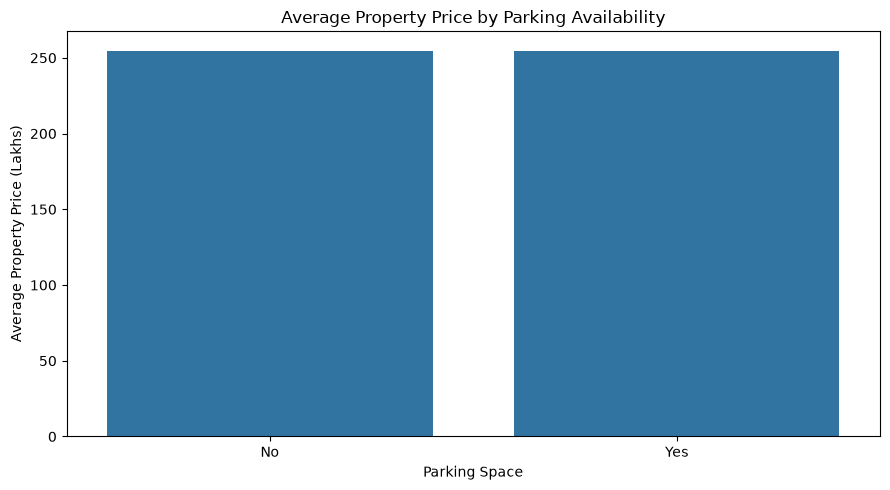

In [104]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=parking_price,
    x="Parking_Space",
    y="Average_Price"
)

plt.title("Average Property Price by Parking Availability")
plt.xlabel("Parking Space")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

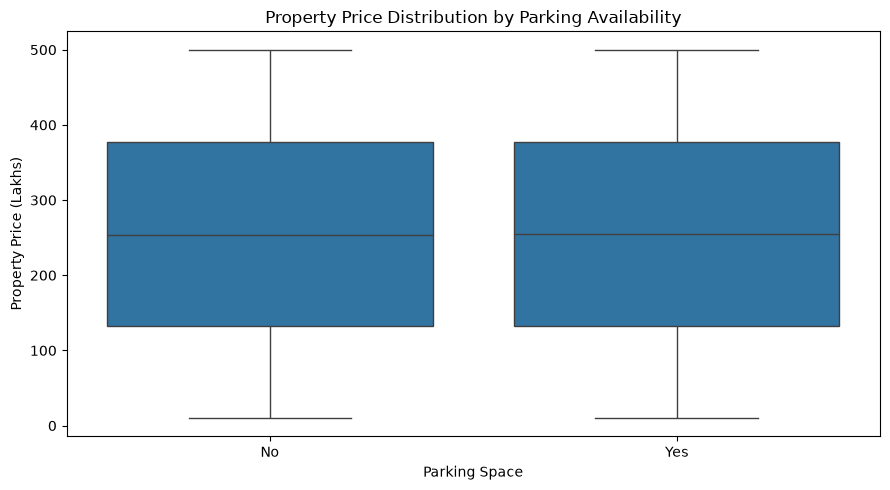

In [105]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Parking_Space",
    y="Price_in_Lakhs"
)

plt.title("Property Price Distribution by Parking Availability")
plt.xlabel("Parking Space")
plt.ylabel("Property Price (Lakhs)")

plt.tight_layout()
plt.show()

In [106]:
highest_parking_price = parking_price.loc[
    parking_price["Average_Price"].idxmax()
]

print("Parking category with highest average price:")

print(highest_parking_price)

Parking category with highest average price:
Parking_Space            Yes
Average_Price     254.745492
Median_Price          254.36
Property_Count        124544
Name: 1, dtype: object


The analysis compares property prices across different parking categories. Properties in the YES category have the highest average price of 254.745492 lakhs. This suggests an association between parking availability and property prices in this dataset. However, it does not prove that parking alone causes higher prices.